In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

DATA_PATH = "data/superstore.csv"
OUTPUT_DIR = "output"
CHART_DIR = os.path.join(OUTPUT_DIR, "charts")
os.makedirs(CHART_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("Columns:", len(df.columns))

Dataset shape: (51290, 27)
Columns: 27


In [2]:
if '记录数' in df.columns:
    df = df.drop(columns=['记录数'])
df['Order.Date'] = pd.to_datetime(df['Order.Date'], errors='coerce')
df['Ship.Date'] = pd.to_datetime(df['Ship.Date'], errors='coerce')
df['Shipping_Days'] = (df['Ship.Date'] - df['Order.Date']).dt.days

customer_df = df.groupby(['Customer.ID','Customer.Name'], as_index=False).agg(
    Total_Sales=('Sales','sum'),
    Total_Profit=('Profit','sum'),
    Total_Quantity=('Quantity','sum'),
    Number_of_Orders=('Order.ID','nunique'),
    Average_Order_Value=('Sales','mean'),
    Avg_Discount=('Discount','mean')
)
features = ['Total_Sales','Total_Profit','Total_Quantity','Number_of_Orders','Average_Order_Value']
customer_df[features] = customer_df[features].replace([np.inf,-np.inf],np.nan).fillna(customer_df[features].median())
print("Unique customers:", len(customer_df))
customer_df.head()

Unique customers: 4873


,Customer.ID,Customer.Name,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders,Average_Order_Value,Avg_Discount
0,AA-103151,Alex Avila,1445,12.8760,44,5,144.500000,0.270000
1,AA-103152,Alex Avila,6105,568.7370,50,7,381.562500,0.040625
2,AA-103153,Alex Avila,633,228.9600,21,2,126.600000,0.000000
3,AA-103154,Alex Avila,5565,-362.8825,30,5,505.909091,0.090909
4,AA-103751,Allen Armold,2407,577.9350,35,4,267.444444,0.066667


In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customer_df[features])

ks = list(range(2,9))
inertias, silhouettes = [], []
for k in ks:
    m = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = m.fit_predict(X_scaled)
    inertias.append(m.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

metrics = pd.DataFrame({'k':ks,'inertia':inertias,'silhouette_score':silhouettes})
metrics.to_csv(os.path.join(OUTPUT_DIR,'k_selection_metrics.csv'),index=False)
metrics

C:\Users\Prajwal\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Prajwal\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\Prajwal\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Prajwal\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^

,k,inertia,silhouette_score
0,2,14723.995264,0.406616
1,3,11838.042579,0.350686
2,4,10212.087681,0.361819
3,5,9072.229801,0.295676
4,6,8176.850547,0.288918
5,7,7488.209971,0.290336
6,8,6989.124713,0.296994


In [4]:
model = KMeans(n_clusters=4, random_state=42, n_init=20)
customer_df['Cluster'] = model.fit_predict(X_scaled)
# Remap cluster IDs in ascending order of average sales for stable interpretation.
order = customer_df.groupby('Cluster')['Total_Sales'].mean().sort_values().index.tolist()
remap = {old:new for new,old in enumerate(order)}
customer_df['Cluster'] = customer_df['Cluster'].map(remap)
segment_names = {0:'Low-Value / Occasional',1:'Moderate-Value / Occasional',2:'Frequent / Moderate-Value',3:'High-Value / Frequent'}
customer_df['Segment_Name'] = customer_df['Cluster'].map(segment_names)
profile = customer_df.groupby('Cluster').agg(
    Customers=('Customer.ID','count'), Avg_Sales=('Total_Sales','mean'), Avg_Profit=('Total_Profit','mean'),
    Avg_Quantity=('Total_Quantity','mean'), Avg_Orders=('Number_of_Orders','mean'), Avg_AOV=('Average_Order_Value','mean'),
    Total_Sales=('Total_Sales','sum'), Total_Profit=('Total_Profit','sum')
).reset_index()
profile['Sales_Share_%'] = profile['Total_Sales']/customer_df['Total_Sales'].sum()*100
profile['Profit_Share_%'] = profile['Total_Profit']/customer_df['Total_Profit'].sum()*100
profile['Customer_Share_%'] = profile['Customers']/len(customer_df)*100
profile['Segment_Name'] = profile['Cluster'].map(segment_names)
profile

,Cluster,Customers,Avg_Sales,Avg_Profit,Avg_Quantity,Avg_Orders,Avg_AOV,Total_Sales,Total_Profit,Sales_Share_%,Profit_Share_%,Customer_Share_%,Segment_Name
0,0,2310,819.767965,37.665107,15.906494,3.178788,137.745710,1893664,87006.39742,14.978077,5.929058,47.404063,Low-Value / Occasional
1,1,1556,3147.345758,208.297555,54.779563,7.410026,217.676633,4897270,324110.99572,38.735322,22.086571,31.931049,Moderate-Value / Occasional
2,2,527,4049.478178,789.951549,31.867173,4.480076,526.983502,2134075,416304.46646,16.879625,28.369103,10.814693,Frequent / Moderate-Value
3,3,480,7745.616667,1333.407149,82.368750,9.414583,393.568588,3717896,640035.43168,29.406976,43.615268,9.850195,High-Value / Frequent


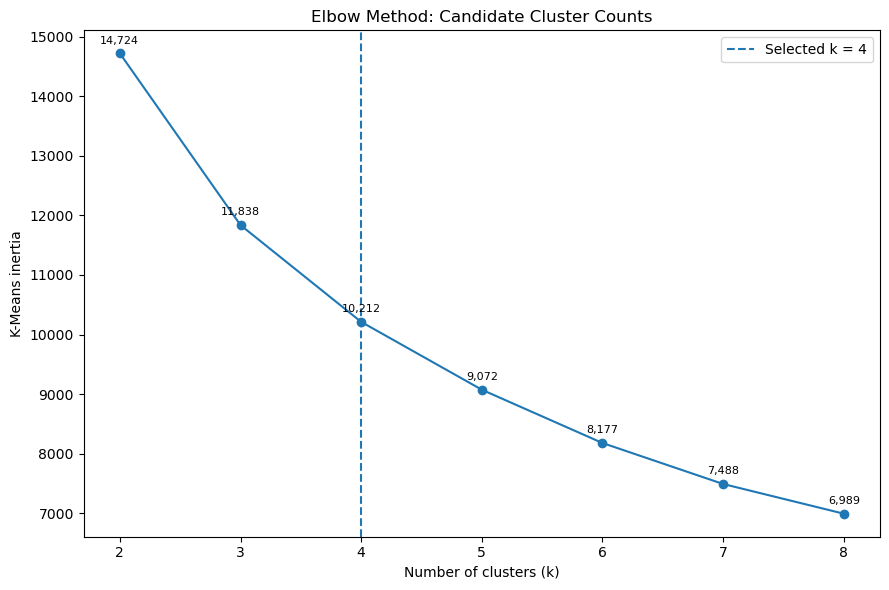

In [5]:
plt.figure(figsize=(9,6)); plt.plot(ks,inertias,marker='o'); plt.axvline(4,ls='--',label='Selected k = 4')
for x,y in zip(ks,inertias): plt.annotate(f'{y:,.0f}',(x,y),textcoords='offset points',xytext=(0,7),ha='center',fontsize=8)
plt.title('Elbow Method: Candidate Cluster Counts'); plt.xlabel('Number of clusters (k)'); plt.ylabel('K-Means inertia'); plt.legend(); plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'01_elbow_curve.png'),dpi=180,bbox_inches='tight'); plt.show()

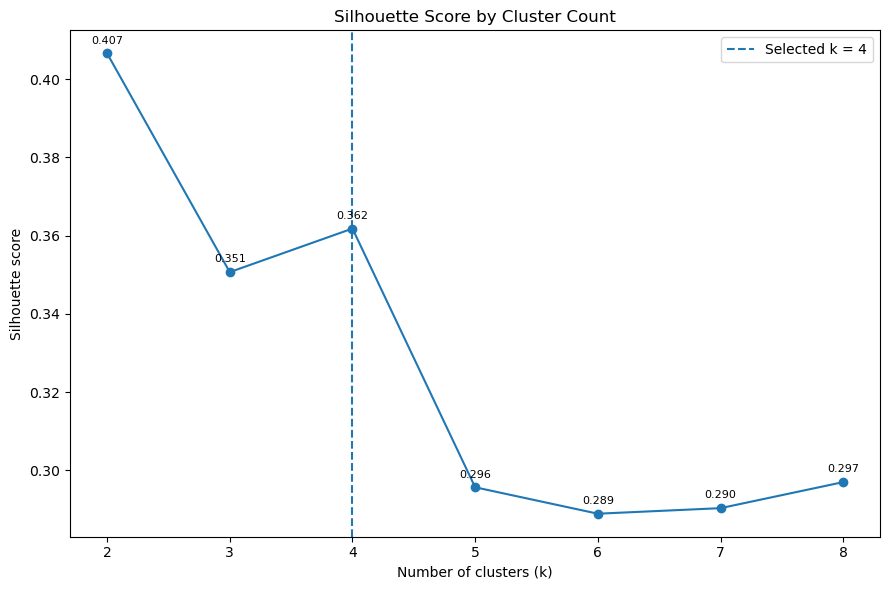

In [6]:
plt.figure(figsize=(9,6)); plt.plot(ks,silhouettes,marker='o'); plt.axvline(4,ls='--',label='Selected k = 4')
for x,y in zip(ks,silhouettes): plt.annotate(f'{y:.3f}',(x,y),textcoords='offset points',xytext=(0,7),ha='center',fontsize=8)
plt.title('Silhouette Score by Cluster Count'); plt.xlabel('Number of clusters (k)'); plt.ylabel('Silhouette score'); plt.legend(); plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'02_silhouette_scores.png'),dpi=180,bbox_inches='tight'); plt.show()

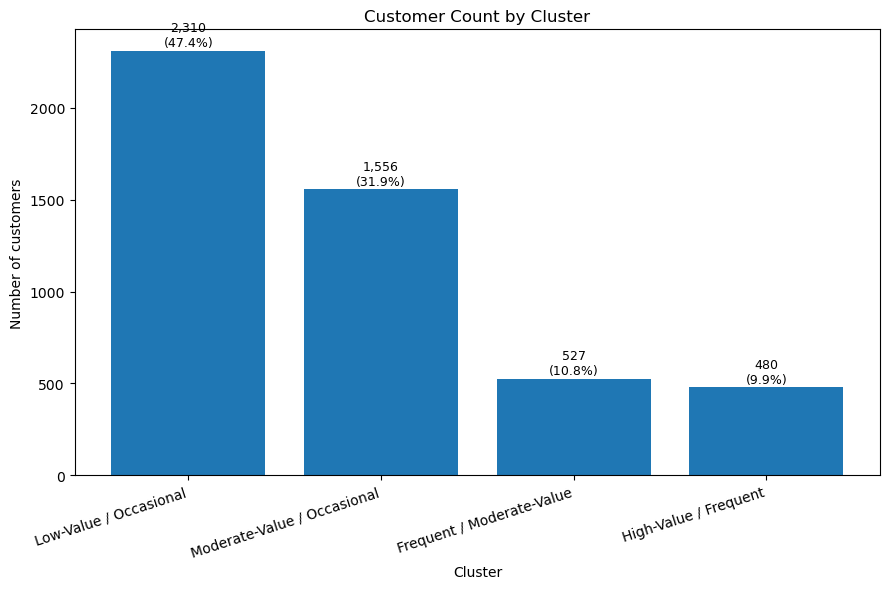

In [7]:
sizes=customer_df['Cluster'].value_counts().sort_index(); plt.figure(figsize=(9,6)); bars=plt.bar([segment_names[i] for i in sizes.index],sizes.values); plt.title('Customer Count by Cluster'); plt.xlabel('Cluster'); plt.ylabel('Number of customers'); plt.xticks(rotation=18,ha='right')
for b,v in zip(bars,sizes.values): plt.text(b.get_x()+b.get_width()/2,v+25,f'{v:,}\n({v/len(customer_df)*100:.1f}%)',ha='center',fontsize=9)
plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'03_cluster_distribution.png'),dpi=180,bbox_inches='tight'); plt.show()

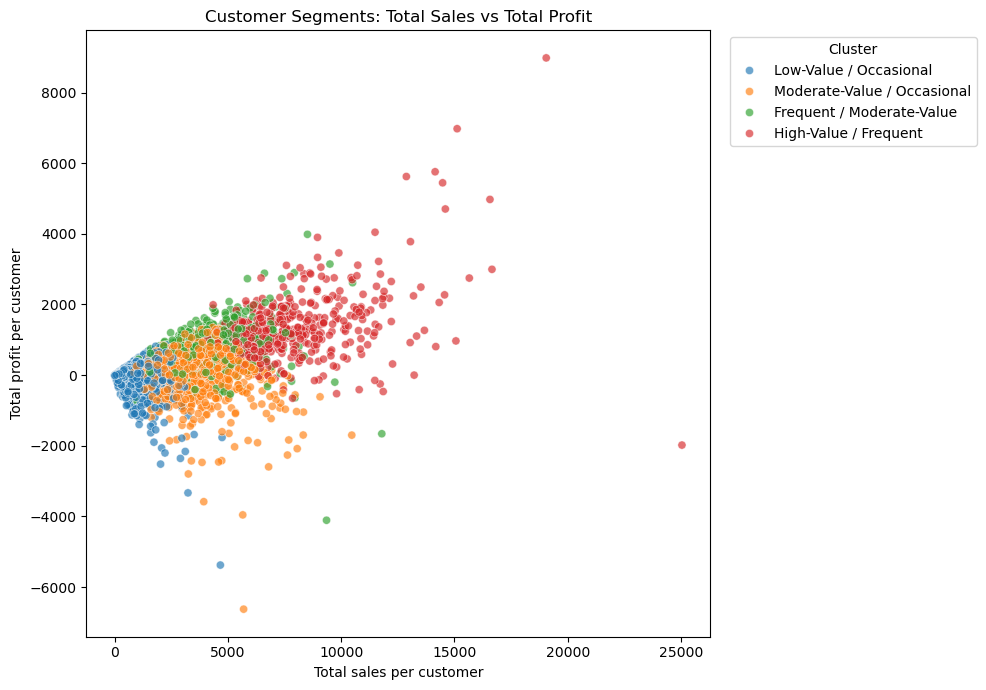

In [8]:
plt.figure(figsize=(10,7)); sns.scatterplot(data=customer_df,x='Total_Sales',y='Total_Profit',hue='Segment_Name',s=35,alpha=.65); plt.title('Customer Segments: Total Sales vs Total Profit'); plt.xlabel('Total sales per customer'); plt.ylabel('Total profit per customer'); plt.legend(title='Cluster',bbox_to_anchor=(1.02,1),loc='upper left'); plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'04_sales_profit_clusters.png'),dpi=180,bbox_inches='tight'); plt.show()

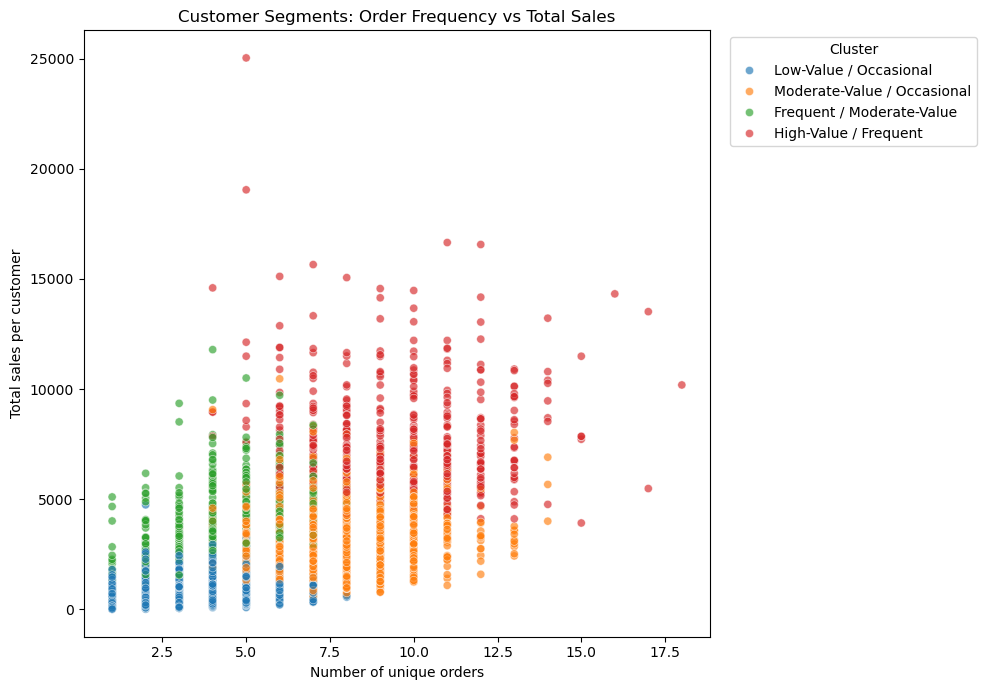

In [9]:
plt.figure(figsize=(10,7)); 
sns.scatterplot(data=customer_df,x='Number_of_Orders',y='Total_Sales',hue='Segment_Name',s=35,alpha=.65); plt.title('Customer Segments: Order Frequency vs Total Sales'); plt.xlabel('Number of unique orders'); plt.ylabel('Total sales per customer'); plt.legend(title='Cluster',bbox_to_anchor=(1.02,1),loc='upper left'); plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'05_orders_sales_clusters.png'),dpi=180,bbox_inches='tight'); plt.show()

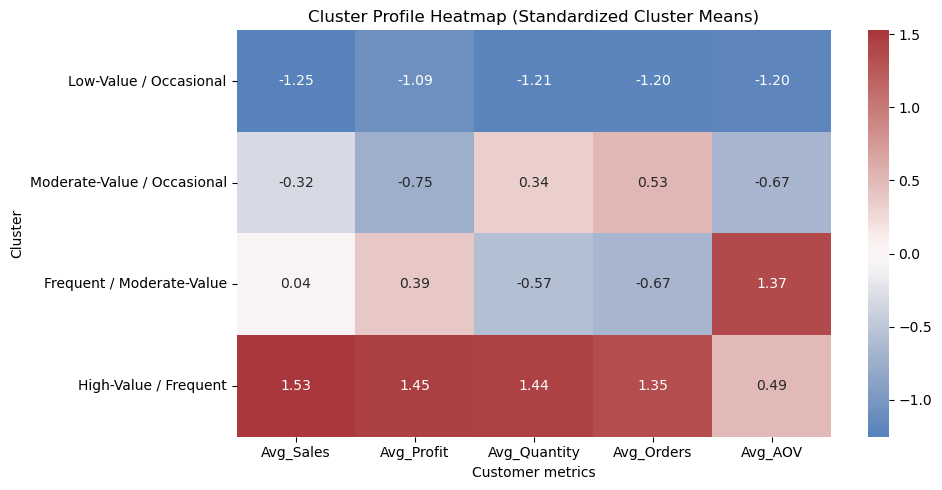

In [10]:
heat=profile.set_index('Segment_Name')[['Avg_Sales','Avg_Profit','Avg_Quantity','Avg_Orders','Avg_AOV']]; zn=(heat-heat.mean())/heat.std(ddof=0); plt.figure(figsize=(10,5)); sns.heatmap(zn,annot=True,fmt='.2f',center=0,cmap='vlag'); plt.title('Cluster Profile Heatmap (Standardized Cluster Means)'); plt.xlabel('Customer metrics'); plt.ylabel('Cluster'); plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'06_cluster_profile_heatmap.png'),dpi=180,bbox_inches='tight'); plt.show()

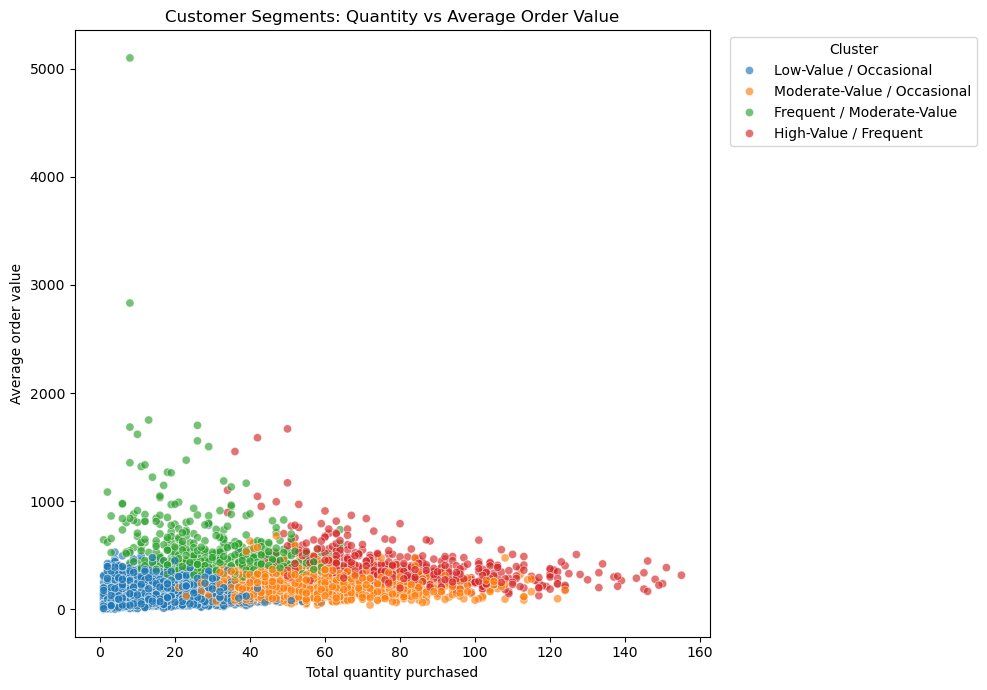

In [11]:
plt.figure(figsize=(10,7)); sns.scatterplot(data=customer_df,x='Total_Quantity',y='Average_Order_Value',hue='Segment_Name',s=35,alpha=.65); plt.title('Customer Segments: Quantity vs Average Order Value'); plt.xlabel('Total quantity purchased'); plt.ylabel('Average order value'); plt.legend(title='Cluster',bbox_to_anchor=(1.02,1),loc='upper left'); plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'07_quantity_aov.png'),dpi=180,bbox_inches='tight'); plt.show()

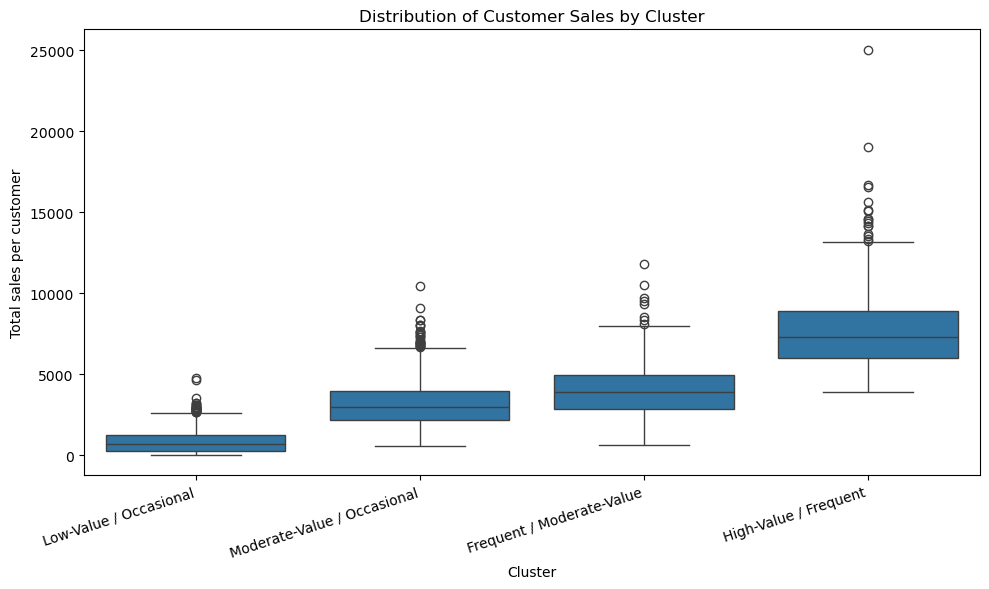

In [12]:
plt.figure(figsize=(10,6)); sns.boxplot(data=customer_df,x='Segment_Name',y='Total_Sales'); plt.title('Distribution of Customer Sales by Cluster'); plt.xlabel('Cluster'); plt.ylabel('Total sales per customer'); plt.xticks(rotation=18,ha='right'); plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'08_sales_boxplot.png'),dpi=180,bbox_inches='tight'); plt.show()

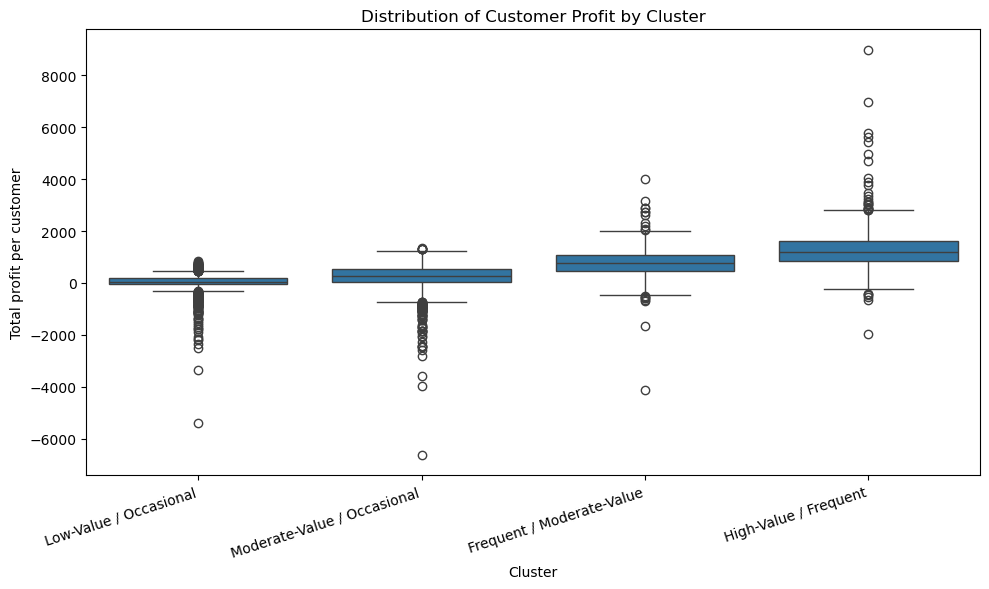

In [13]:
plt.figure(figsize=(10,6)); sns.boxplot(data=customer_df,x='Segment_Name',y='Total_Profit'); plt.title('Distribution of Customer Profit by Cluster'); plt.xlabel('Cluster'); plt.ylabel('Total profit per customer'); plt.xticks(rotation=18,ha='right'); plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'09_profit_boxplot.png'),dpi=180,bbox_inches='tight'); plt.show()

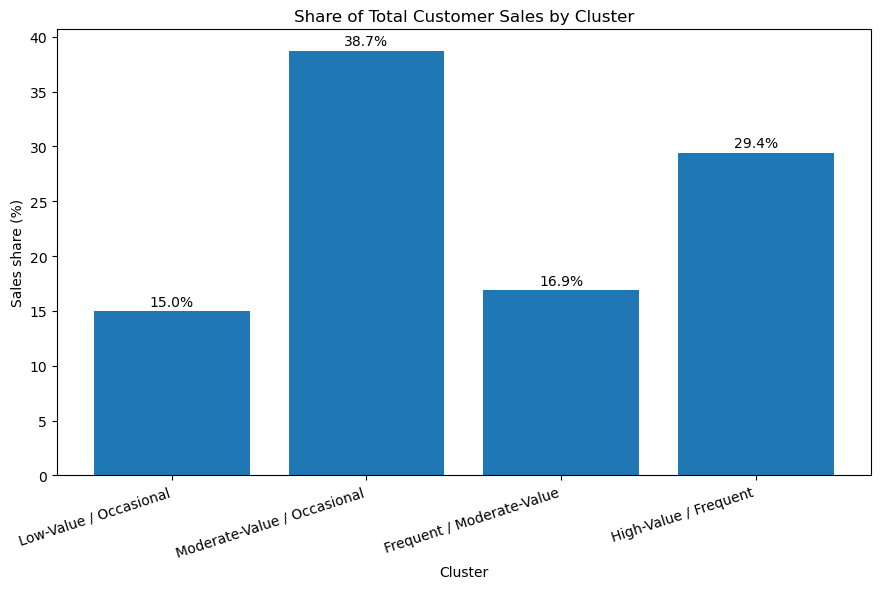

In [14]:
plt.figure(figsize=(9,6)); bars=plt.bar(profile['Segment_Name'],profile['Sales_Share_%']); plt.title('Share of Total Customer Sales by Cluster'); plt.xlabel('Cluster'); plt.ylabel('Sales share (%)'); plt.xticks(rotation=18,ha='right')
for b,v in zip(bars,profile['Sales_Share_%']): plt.text(b.get_x()+b.get_width()/2,v+0.5,f'{v:.1f}%',ha='center')
plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'10_sales_share.png'),dpi=180,bbox_inches='tight'); plt.show()

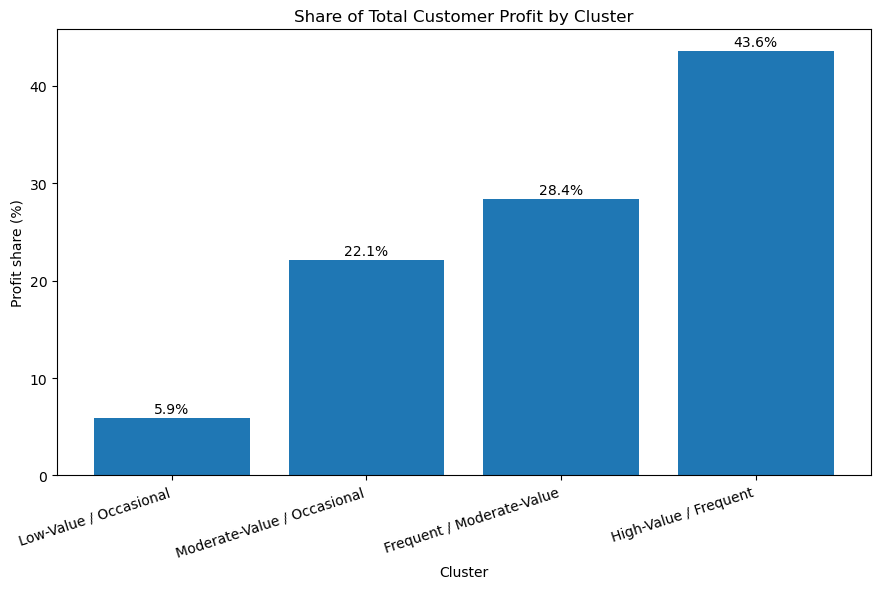

In [15]:
plt.figure(figsize=(9,6)); bars=plt.bar(profile['Segment_Name'],profile['Profit_Share_%']); plt.title('Share of Total Customer Profit by Cluster'); plt.xlabel('Cluster'); plt.ylabel('Profit share (%)'); plt.xticks(rotation=18,ha='right')
for b,v in zip(bars,profile['Profit_Share_%']): plt.text(b.get_x()+b.get_width()/2,v+0.5,f'{v:.1f}%',ha='center')
plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'11_profit_share.png'),dpi=180,bbox_inches='tight'); plt.show()

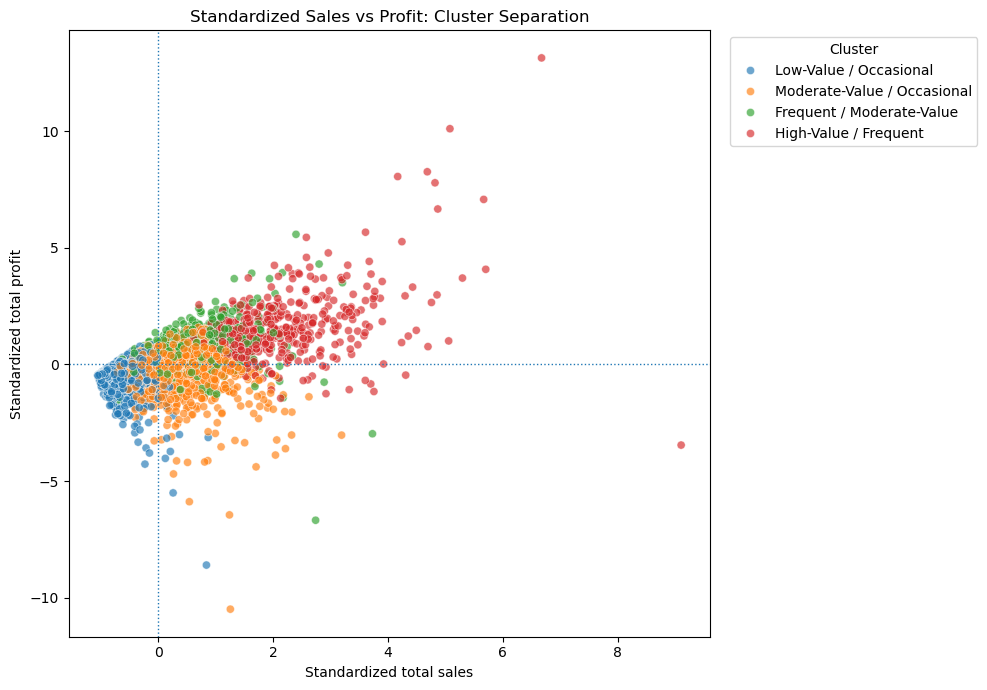

In [16]:
xy=pd.DataFrame(X_scaled[:,[0,1]],columns=['Sales_z','Profit_z']); xy['Segment_Name']=customer_df['Segment_Name'].values; plt.figure(figsize=(10,7)); sns.scatterplot(data=xy,x='Sales_z',y='Profit_z',hue='Segment_Name',s=35,alpha=.65); plt.axhline(0,ls=':',lw=1); plt.axvline(0,ls=':',lw=1); plt.title('Standardized Sales vs Profit: Cluster Separation'); plt.xlabel('Standardized total sales'); plt.ylabel('Standardized total profit'); plt.legend(title='Cluster',bbox_to_anchor=(1.02,1),loc='upper left'); plt.tight_layout(); plt.savefig(os.path.join(CHART_DIR,'12_standardized_2d_clusters.png'),dpi=180,bbox_inches='tight'); plt.show()

In [17]:
customer_df.to_csv(os.path.join(OUTPUT_DIR,'customer_clusters.csv'),index=False)
profile.to_csv(os.path.join(OUTPUT_DIR,'cluster_profile.csv'),index=False)
print('All charts and outputs generated successfully.')

All charts and outputs generated successfully.
